# 03_5. H2 — heterogeneity of feature importance / H2 — неоднородность важности признаков

**EN.** **H2:** the importance of features differs between borrowers. If it did not, one set of weights for everybody (an ordinary scorecard) would be enough, and per-borrower feature weights (the TFWT idea of the hybrid, stage 4) would have nothing to add. **H₀:** feature × segment interactions do not improve the model. **Decision rule** (fixed before the experiments): LR-test p < 0.05 **and** Δlog-loss on validation > 0.

**How we test.** Two logistic regressions on the WoE values of the 18 selected features (as in B0):
- *restricted*: one coefficient per feature + a level per segment;
- *full*: in addition, every feature gets its own extra coefficient in every segment (feature × segment **interactions**), i.e. its effect may differ between segments.

The **likelihood-ratio (LR) test** compares how much better the full model explains the train data: LR = 2 (ll_full − ll_restricted), where ll is the log-likelihood; under H₀ it follows a χ² distribution with df = 18 × (number of segments − 1) = 36. With 2.3 M rows almost any difference is "significant", so the **effect size** decides: the drop of log-loss on validation (data the models have not seen).

**Segments, fixed in the test protocol before this run:** FICO at origination < 680 / 680–739 / ≥ 740 — the usual subprime / near-prime / prime tiers of US mortgage lending, and the borrower dimension along which stage 2 found the strongest signal. Sensitivity: current MTM LTV ≤ 80 / 80–95 / > 95 (equity cushion). Missing FICO → < 680, missing LTV → ≤ 80.

**Technical notes.** The regressions are fitted **without weights** on the r = 0.2 train: negatives are drawn independently of the features, so the slopes are unbiased and only the intercept shifts (case-control sampling); a weighted likelihood would not give a valid LR statistic. Snapshots of one loan are dependent, so the p-value is optimistic; as a check the LR test is repeated on one random snapshot per loan. For Δlog-loss both models are calibrated by Platt on half B and evaluated on half A, with a cluster bootstrap CI by loan.

**RU.** **H2:** важность признаков различается между заёмщиками. Если бы это было не так, хватило бы одного набора весов для всех (обычной скоринговой карты), и персональным весам признаков (идея TFWT в гибриде, этап 4) было бы нечего добавить. **H₀:** взаимодействия «признак × сегмент» не улучшают модель. **Решающее правило** (зафиксировано до экспериментов): p LR-теста < 0,05 **и** Δlog-loss на validation > 0.

**Как проверяем.** Две логистические регрессии на WoE-значениях 18 отобранных признаков (как в B0):
- *ограниченная*: один коэффициент на признак + уровень для каждого сегмента;
- *полная*: дополнительно у каждого признака свой добавочный коэффициент в каждом сегменте (**взаимодействия** «признак × сегмент»), то есть эффект признака может различаться между сегментами.

**Тест отношения правдоподобия (LR test)** сравнивает, насколько лучше полная модель объясняет данные train: LR = 2 (ll_полной − ll_ограниченной), где ll — логарифм правдоподобия; при H₀ он распределён как χ² с df = 18 × (число сегментов − 1) = 36. При 2,3 млн строк «значимо» почти любое различие, поэтому решает **размер эффекта**: снижение log-loss на validation (данных, которых модели не видели).

**Сегменты, зафиксированные в протоколе test до этого расчёта:** FICO при выдаче < 680 / 680–739 / ≥ 740 — привычные уровни subprime / near-prime / prime в американской ипотеке и то измерение заёмщика, по которому на этапе 2 найден самый сильный сигнал. Чувствительность: текущий MTM LTV ≤ 80 / 80–95 / > 95 (запас собственного капитала в залоге). Пропуск FICO → < 680, пропуск LTV → ≤ 80.

**Технические замечания.** Регрессии обучаются **без весов** на train с r = 0,2: отрицательные примеры отобраны независимо от признаков, поэтому наклоны несмещены, сдвигается только свободный член (выборка «случай — контроль»); взвешенное правдоподобие не дало бы корректной LR-статистики. Снимки одного кредита зависимы, поэтому p-value оптимистично; для проверки LR test повторяется на одном случайном снимке на кредит. Для Δlog-loss обе модели калибруются Платтом на половине B и оцениваются на половине A, интервал — кластерный bootstrap по кредиту.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import gc
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

from xai_ews.config import feature_config
from xai_ews.evaluation.heterogeneity import SEGMENTS, design, lr_interaction_test, segment_codes
from xai_ews.evaluation.metrics import auc, log_loss
from xai_ews.evaluation.stats import cluster_bootstrap, one_snapshot_per_loan, weighted_auc_fn
from xai_ews.models import scorecard as sc
from xai_ews.models.calibration import Platt
from xai_ews.models.data import load_eval, load_train
from xai_ews.paths import MODELING_DIR

SEL = feature_config()["selected"]
FEATURES, CATS = SEL["features"], SEL["categorical"]
SEED = 20261025
TASKS = ("y1",)

### 1. LR test on train / LR test на train

**EN.** For each segmentation (task Y1): log-likelihoods of both models, the LR statistic, df and p-value — on all train snapshots and on one random snapshot per loan.

**RU.** Для каждой сегментации (задача Y1): логарифмы правдоподобия обеих моделей, LR-статистика, df и p-value — на всех снимках train и на одном случайном снимке на кредит.

In [2]:
tests, fitted, val = [], {}, {}
for task in TASKS:
    tr = load_train(task, FEATURES, CATS)
    x, y = sc.woe_matrix(tr, FEATURES, task), tr[task].to_numpy()
    one = one_snapshot_per_loan(tr["loan_identifier"].to_numpy(), seed=SEED)
    va = load_eval("validation", task, FEATURES, CATS)
    val[task] = (va.select("loan_identifier", task, "half"), sc.woe_matrix(va, FEATURES, task),
                 {k: segment_codes(va[SEGMENTS[k][0]].to_numpy(), k) for k in SEGMENTS})
    for kind, (col, _, labels) in SEGMENTS.items():
        seg = segment_codes(tr[col].to_numpy(), kind)
        for sample, idx in (("all snapshots", slice(None)), ("one snapshot per loan", one)):
            r = lr_interaction_test(x[idx], seg[idx], y[idx], len(labels))
            tests.append({"task": task, "segments": kind, "sample": sample, "rows": int(len(y[idx])),
                          "events": int(y[idx].sum()), **{k: r[k] for k in ("ll_restricted", "ll_full", "lr_stat", "df", "p")}})
            if sample == "all snapshots":
                fitted[(task, kind)] = (r["restricted"], r["full"])
            print(task, kind, sample, f"LR = {r['lr_stat']:,.1f}, df = {r['df']}, p = {r['p']:.2e}", flush=True)
    del tr, x, va; gc.collect()
tests = pd.DataFrame(tests)
tests.to_csv(MODELING_DIR / "h2_lr_tests.csv", index=False)
tests

y1 fico all snapshots LR = 419.7, df = 36, p = 6.70e-67


y1 fico one snapshot per loan LR = 212.8, df = 36, p = 5.99e-27


y1 mtm_ltv all snapshots LR = 268.8, df = 36, p = 2.05e-37


y1 mtm_ltv one snapshot per loan LR = 117.1, df = 36, p = 1.64e-10


,task,segments,sample,rows,events,ll_restricted,ll_full,lr_stat,df,p
0,y1,fico,all snapshots,2294292,14062,"-72,357.8482","-72,148.0112",419.6740,36,0.0000
1,y1,fico,one snapshot per loan,1239248,6209,"-33,029.1583","-32,922.7708",212.7749,36,0.0000
2,y1,mtm_ltv,all snapshots,2294292,14062,"-72,388.0663","-72,253.6418",268.8490,36,0.0000
3,y1,mtm_ltv,one snapshot per loan,1239248,6209,"-33,043.8632","-32,985.3139",117.0986,36,0.0000


**EN. How to read.** Every LR test rejects H₀ by a wide margin. FICO segments: LR = 420 with df = 36, p ≈ 7·10⁻⁶⁷; on one snapshot per loan (1.24 M independent rows, 6,209 events) still LR = 213, p ≈ 6·10⁻²⁷. MTM LTV segments: LR = 269 (one snapshot per loan 117, p ≈ 2·10⁻¹⁰). So on the training data the feature effects do differ between borrower segments. With 2.3 M rows this was expected; the effect size below decides.

**RU. Как читать.** Все LR-тесты уверенно отвергают H₀. Сегменты FICO: LR = 420 при df = 36, p ≈ 7·10⁻⁶⁷; на одном снимке на кредит (1,24 млн независимых строк, 6 209 событий) по-прежнему LR = 213, p ≈ 6·10⁻²⁷. Сегменты MTM LTV: LR = 269 (один снимок на кредит — 117, p ≈ 2·10⁻¹⁰). Значит, на обучающих данных эффекты признаков действительно различаются между сегментами заёмщиков. При 2,3 млн строк этого и следовало ждать; решает размер эффекта ниже.

### 2. Effect size on validation / Размер эффекта на validation

**EN.** Both models are calibrated by Platt on half B and evaluated on half A. Δlog-loss = log-loss(restricted) − log-loss(full): **positive = interactions help** on new data. Also ΔAUC = AUC(full) − AUC(restricted). 95 % CIs: cluster bootstrap by loan, B = 1000.

**RU.** Обе модели калибруются Платтом на половине B и оцениваются на половине A. Δlog-loss = log-loss(ограниченной) − log-loss(полной): **больше 0 — взаимодействия помогают** на новых данных. Также ΔAUC = AUC(полной) − AUC(ограниченной). 95 %-е интервалы — кластерный bootstrap по кредиту, B = 1000.

In [3]:
effects = []
for task in TASKS:
    keys, xv, segs = val[task]
    a, b = (keys["half"] == "A").to_numpy(), (keys["half"] == "B").to_numpy()
    y = keys[task].to_numpy()
    for kind, (_, _, labels) in SEGMENTS.items():
        m0, m1 = fitted[(task, kind)]
        z0 = m0.decision_function(design(xv, segs[kind], len(labels), False))
        z1 = m1.decision_function(design(xv, segs[kind], len(labels), True))
        p0 = Platt().fit(z0[b], y[b]).predict(z0[a])
        p1 = Platt().fit(z1[b], y[b]).predict(z1[a])
        ya = y[a]
        res = cluster_bootstrap(
            {"ll_restricted": lambda w: log_loss(ya, p0, w), "ll_full": lambda w: log_loss(ya, p1, w),
             "auc_full": weighted_auc_fn(ya, p1), "auc_restricted": weighted_auc_fn(ya, p0)},
            keys["loan_identifier"].to_numpy()[a], b=1000, seed=SEED,
            diffs=[("ll_restricted", "ll_full"), ("auc_full", "auc_restricted")])
        effects.append(res.assign(task=task, segments=kind))
effects = pd.concat(effects, ignore_index=True)
effects.to_csv(MODELING_DIR / "h2_validation_effect.csv", index=False)
effects.pivot_table(index=["task", "segments"], columns="metric", values=["value", "lo", "hi"]) \
    .swaplevel(axis=1).sort_index(axis=1)[["ll_restricted - ll_full", "auc_full - auc_restricted"]]

metric        ll_restricted - ll_full                 auc_full - auc_restricted                
                                   hi      lo   value                        hi      lo   value
task segments                                                                                  
y1   fico                      0.0001  0.0000  0.0000                    0.0018 -0.0012  0.0002
     mtm_ltv                  -0.0000 -0.0000 -0.0000                   -0.0001 -0.0025 -0.0012

**EN. How to read.** **FICO segments (primary):** Δlog-loss = +0.000031 [+0.000008; +0.000056] — the interactions improve the forecast on new data and the CI is above 0 (0.5 % of bootstrap draws ≤ 0), but the gain is only 0.25 % of the log-loss (0.01255); ΔAUC +0.0002 [−0.0012; +0.0018], not significant. **MTM LTV (sensitivity):** Δlog-loss = −0.000021 [−0.000040; −0.000004] and ΔAUC −0.0012 — the interactions overfit and make validation slightly worse. In a linear WoE model the heterogeneity across FICO tiers is real but small; how much a flexible per-borrower model can gain from it is the question of the hybrid (H1, stage 4).

**RU. Как читать.** **Сегменты FICO (основной вариант):** Δlog-loss = +0,000031 [+0,000008; +0,000056] — взаимодействия улучшают прогноз на новых данных, интервал выше 0 (0,5 % bootstrap-повторов ≤ 0), но выигрыш всего 0,25 % log-loss (0,01255); ΔAUC +0,0002 [−0,0012; +0,0018], незначимо. **MTM LTV (чувствительность):** Δlog-loss = −0,000021 [−0,000040; −0,000004] и ΔAUC −0,0012 — взаимодействия переобучаются и немного ухудшают validation. В линейной WoE-модели неоднородность между уровнями FICO реальна, но мала; сколько из неё может извлечь гибкая модель с персональными весами — вопрос гибрида (H1, этап 4).

### 3. Which features change their effect / Какие признаки меняют эффект

**EN.** From the full model with FICO segments: the slope of each feature's WoE in each segment (base coefficient + interaction). Equal slopes = the same importance for every borrower. Shown: the 10 features with the largest spread of slopes between segments.

**RU.** Из полной модели с сегментами FICO: наклон WoE каждого признака в каждом сегменте (базовый коэффициент + взаимодействие). Одинаковые наклоны — одинаковая важность для всех заёмщиков. Показаны 10 признаков с наибольшим разбросом наклонов между сегментами.

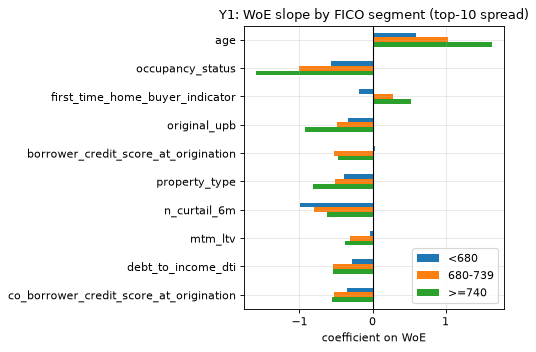

,<680,680-739,>=740,spread,task
age,0.5920,1.0389,1.6383,1.0463,y1
occupancy_status,-0.5749,-1.0136,-1.6001,1.0252,y1
first_time_home_buyer_indicator,-0.1878,0.2842,0.5337,0.7214,y1
original_upb,-0.3300,-0.4865,-0.9314,0.6013,y1
borrower_credit_score_at_origination,0.0313,-0.5281,-0.4711,0.5594,y1
property_type,-0.3844,-0.5188,-0.8107,0.4262,y1
n_curtail_6m,-0.9926,-0.7980,-0.6218,0.3708,y1
mtm_ltv,-0.0392,-0.3027,-0.3749,0.3357,y1
debt_to_income_dti,-0.2776,-0.5456,-0.5468,0.2693,y1
co_borrower_credit_score_at_origination,-0.3515,-0.5343,-0.5574,0.2059,y1


In [4]:
labels = SEGMENTS["fico"][2]
K = len(FEATURES)
slopes = []
for task in TASKS:
    m1 = fitted[(task, "fico")][1]
    c = m1.coef_[0]
    base = c[:K]
    inter = c[K + len(labels) - 1:].reshape(len(labels) - 1, K)
    s = pd.DataFrame({labels[0]: base, **{labels[j + 1]: base + inter[j] for j in range(len(labels) - 1)}},
                     index=FEATURES)
    s["spread"] = s[labels].max(axis=1) - s[labels].min(axis=1)
    slopes.append(s.assign(task=task))
slopes = pd.concat(slopes)
slopes.to_csv(MODELING_DIR / "h2_slopes_by_fico.csv")
fig, axes = plt.subplots(1, len(TASKS), figsize=(6.5 * len(TASKS), 4.5), squeeze=False)
for ax, task in zip(axes[0], TASKS):
    s = slopes[slopes["task"] == task].sort_values("spread", ascending=False).head(10)
    s[labels].plot.barh(ax=ax); ax.invert_yaxis(); ax.axvline(0, c="k", lw=1)
    ax.set_title(f"{task.upper()}: WoE slope by FICO segment (top-10 spread)"); ax.set_xlabel("coefficient on WoE")
plt.tight_layout(); plt.show()
slopes.sort_values(["task", "spread"], ascending=[True, False]).groupby("task").head(10)

**EN. How to read.** A coefficient on WoE is negative when the feature works in the same direction as in its own WoE table (higher WoE = safer); the larger |coef|, the stronger; a positive coefficient means the direction is reversed once the other features are in the model. **`occupancy_status`** changes the most: its effect is almost 3× stronger for prime borrowers (FICO ≥ 740: −1.60) than for FICO < 680 (−0.58) — for a borrower with a high score, being an investor or a second-home owner matters much more. **`first_time_home_buyer_indicator`** changes sign: it works in the usual direction for FICO < 680 (−0.19) and in the opposite one for 680–739 and ≥ 740 (+0.28, +0.53). **`age`** has a positive coefficient in every tier, strongest for prime (+0.59 / +1.04 / +1.64): with the current LTV and house prices in the model, older loans are riskier than their WoE says — consistent with the sign remark on `age` in stage 2. Loan size and property type are also stronger in the prime tier; the FICO WoE itself adds almost nothing inside the < 680 tier (+0.03), as expected, since the tier already holds that information. Behaviour features work the other way round: the number of curtailments (`n_curtail_6m`) matters most for FICO < 680 (−0.99 vs −0.62).

**RU. Как читать.** Коэффициент при WoE отрицателен, если признак действует в ту же сторону, что в его таблице WoE (больше WoE — безопаснее); чем больше |коэф.|, тем сильнее; положительный коэффициент значит, что при остальных признаках в модели направление обратное. Сильнее всего меняется **`occupancy_status`**: у prime-заёмщиков (FICO ≥ 740: −1,60) его эффект почти в 3 раза сильнее, чем при FICO < 680 (−0,58) — для заёмщика с высоким баллом то, что он инвестор или владелец второго дома, значит гораздо больше. **`first_time_home_buyer_indicator`** меняет знак: при FICO < 680 действует в обычную сторону (−0,19), при 680–739 и ≥ 740 — в обратную (+0,28 и +0,53). У **`age`** коэффициент положителен во всех группах и сильнее всего у prime (+0,59 / +1,04 / +1,64): при текущем LTV и ценах жилья в модели более старые кредиты рискованнее, чем говорит их WoE, — это согласуется с замечанием о знаке `age` на этапе 2. Сумма кредита и тип объекта тоже сильнее в prime-группе; сам WoE FICO внутри группы < 680 почти ничего не добавляет (+0,03), как и ожидалось: группа уже содержит эту информацию. Поведенческие признаки ведут себя наоборот: число частичных досрочных погашений (`n_curtail_6m`) важнее всего при FICO < 680 (−0,99 против −0,62).

In [5]:
v = effects[effects["metric"] == "ll_restricted - ll_full"].set_index(["task", "segments"])
t = tests[tests["sample"] == "all snapshots"].set_index(["task", "segments"])
t1 = tests[tests["sample"] == "one snapshot per loan"].set_index(["task", "segments"])
verdict = pd.DataFrame({"lr_p": t["p"], "lr_p_one_snapshot": t1["p"], "delta_logloss": v["value"],
                        "delta_lo": v["lo"], "delta_hi": v["hi"]})
verdict["H2_rule (p<0.05 and Δ>0)"] = (verdict["lr_p"] < 0.05) & (verdict["delta_logloss"] > 0)
verdict["Δ CI above 0"] = verdict["delta_lo"] > 0
verdict.to_csv(MODELING_DIR / "h2_verdict.csv")
verdict

lr_p  lr_p_one_snapshot  delta_logloss  delta_lo  delta_hi  H2_rule (p<0.05 and Δ>0)  Δ CI above 0
task segments                                                                                                     
y1   fico     0.0000             0.0000         0.0000    0.0000    0.0001                      True          True
     mtm_ltv  0.0000             0.0000        -0.0000   -0.0000   -0.0000                     False         False

**EN. Verdict on H2.** **H2 is confirmed by its decision rule** with the pre-registered FICO segments: LR test p ≈ 7·10⁻⁶⁷ (6·10⁻²⁷ on one snapshot per loan) and Δlog-loss on validation +0.000031 > 0, CI above 0. **The effect is small**: 0.25 % of log-loss in a linear model, no AUC gain; with MTM LTV segments the rule does not hold (Δ < 0). Wording for the paper: feature effects differ significantly between borrower segments (strongest for occupancy, first-time buyers and loan age across FICO tiers), but a segment-interaction scorecard captures only a small part of it; whether per-borrower weights in a flexible model gain more is tested by H1 in stage 4. The verdict is final on validation: H2 is not re-tested on test.

**RU. Вердикт по H2.** **H2 подтверждена по решающему правилу** с заранее зафиксированными сегментами FICO: p LR-теста ≈ 7·10⁻⁶⁷ (6·10⁻²⁷ на одном снимке на кредит) и Δlog-loss на validation +0,000031 > 0, интервал выше 0. **Эффект мал**: 0,25 % log-loss в линейной модели, прироста AUC нет; с сегментами MTM LTV правило не выполняется (Δ < 0). Формулировка для статьи: эффекты признаков значимо различаются между сегментами заёмщиков (сильнее всего — тип проживания, первая покупка и возраст кредита между уровнями FICO), но скоринговая карта с взаимодействиями по сегментам улавливает лишь малую часть этого; даст ли больше персональный вес признаков в гибкой модели — проверяет H1 на этапе 4. Вердикт окончательный на validation: на test H2 не перепроверяется.